# Phase 1 — Project & Data Understanding

This notebook establishes a verified understanding of every raw data source and existing script in the project **before** any crop selection, cleaning, feature engineering or modelling is performed. Nothing in `Dataset/` is modified, and no crop is pre-selected.

## INDEX

1. [Phase Objective](#1)
2. [Project Structure](#2)
3. [Dataset Inventory (Raw Listing)](#3)
4. [Mandi Dataset — India Commodity Wise Mandi Dataset](#4)
5. [APY Dataset — crop-wise-area-production-yield.csv](#5)
6. [APY Codebook](#6)
7. [Agri Market Dataset.csv](#7)
8. [final_data.csv](#8)
9. [Weather API (Open-Meteo) — Existing Script Review](#9)
10. [Existing Code Audit](#10)
11. [Cross-Dataset Compatibility (Initial Check)](#11)
12. [Initial Limitations](#12)
13. [Phase 1 Summary — Dataset Inventory Table](#13)
14. [Requirements for Phase 2](#14)


<a id="1"></a>
## 1. Phase Objective

This phase answers: what datasets exist, what each one actually contains (schema, size, units, date range, purpose), which existing scripts are reusable, what relationships/mismatches exist between the datasets, and what limitations are already visible — so that Phase 2 (crop selection) has a verified, non-assumed foundation to work from.

No cleaning, integration, feature engineering, EDA, crop selection or modelling happens in this phase.

In [1]:
import os
import sys
from pathlib import Path

import pandas as pd
import matplotlib.pyplot as plt

PROJECT_ROOT = Path.cwd().parent if Path.cwd().name == "Notebooks" else Path.cwd()
os.chdir(PROJECT_ROOT)
sys.path.append(str(PROJECT_ROOT))

from Code.utils.data_audit import (
    list_mandi_crop_files,
    load_mandi_file,
    basic_csv_profile,
    parse_mixed_dates,
    MANDI_DIR,
)

pd.set_option("display.max_columns", 50)
plt.rcParams["figure.figsize"] = (9, 4.5)
print("Working directory set to project root:", PROJECT_ROOT)

Working directory set to project root: C:\Users\aksha_q43exq6\OneDrive\Documents\BDA


<a id="2"></a>
## 2. Project Structure

### Verify the actual folder layout

This confirms the real structure on disk rather than assuming it from prior descriptions.

In [2]:
def show_tree(base, max_depth=2, _depth=0, skip_dirs=("India Commodity Wise Mandi Dataset",)):
    if _depth > max_depth:
        return
    entries = sorted(os.listdir(base))
    for name in entries:
        path = os.path.join(base, name)
        prefix = "    " * _depth + "- "
        if os.path.isdir(path):
            note = "  [contents not expanded — inspected separately]" if name in skip_dirs else ""
            print(f"{prefix}{name}/{note}")
            if name not in skip_dirs:
                show_tree(path, max_depth, _depth + 1, skip_dirs)
        else:
            size_mb = os.path.getsize(path) / 1e6
            print(f"{prefix}{name}  ({size_mb:,.2f} MB)")

show_tree(".", max_depth=2)

- Code/
    - inspect_agriculture.py  (0.01 MB)
    - inspect_top.py  (0.00 MB)
    - test_openmeteo.py  (0.00 MB)
    - utils/
        - __init__.py  (0.00 MB)
        - __pycache__/
        - build_phase01_notebook.py  (0.03 MB)
        - data_audit.py  (0.00 MB)
- Dataset/
    - Agri Market Dataset.csv  (3.47 MB)
    - Crop_Wise_Area_Production_Yield_codebook.xlsx  (0.02 MB)
    - India Commodity Wise Mandi Dataset/  [contents not expanded — inspected separately]
    - crop-wise-area-production-yield.csv  (56.22 MB)
    - final_data.csv  (0.18 MB)
- Documentation/
- Notebooks/
    - Phase_01_Project_and_Data_Understanding.ipynb  (0.04 MB)
- Outputs/
    - Figures/
        - phase01_agrimarket_commodity_counts.png  (0.05 MB)
        - phase01_apy_records_per_year.png  (0.04 MB)
        - phase01_top15_mandi_record_counts.png  (0.05 MB)
    - Tables/
- Processed_Data/
    - phase1_mandi_file_record_counts.csv  (0.01 MB)


### Observation

The project root matches the expected layout: `Dataset/` (raw, read-only), `Code/` (scripts + new reusable utils), and the newly created `Notebooks/`, `Processed_Data/`, `Outputs/`, `Documentation/` folders for this milestone's derived work. `Dataset/` is treated as read-only from this point onward — every derived artifact in this notebook is written under `Processed_Data/` or `Outputs/`.

<a id="3"></a>
## 3. Dataset Inventory (Raw Listing)

### List every top-level file in Dataset/ with size

This is a raw structural listing only; detailed profiling of each file follows in the next sections.

In [3]:
dataset_root = Path("Dataset")
for item in sorted(dataset_root.iterdir()):
    if item.is_file():
        print(f"{item.name:55s} {item.stat().st_size/1e6:10,.2f} MB")
    else:
        n_files = len(list(item.iterdir()))
        total_size = sum(f.stat().st_size for f in item.iterdir()) / 1e6
        print(f"{item.name + '/':55s} {n_files} files, {total_size:,.1f} MB total")

Agri Market Dataset.csv                                       3.47 MB
crop-wise-area-production-yield.csv                          56.22 MB
Crop_Wise_Area_Production_Yield_codebook.xlsx                 0.02 MB
final_data.csv                                                0.18 MB
India Commodity Wise Mandi Dataset/                     325 files, 4,745.9 MB total


### Observation

`Dataset/` contains four top-level files (three CSVs + one Excel codebook) and one subfolder (`India Commodity Wise Mandi Dataset/`) holding 325 individual commodity CSVs totalling roughly 3.5 GB. This confirms the mandi data cannot be casually loaded all at once and must be profiled with lightweight, per-file operations (line counts, small `nrows` samples) rather than full loads — the strategy used throughout this notebook and required again in Phase 2's full crop audit.

<a id="4"></a>
## 4. Mandi Dataset — India Commodity Wise Mandi Dataset

### Candidate crop universe

Each CSV in this folder is one commodity. The filename list is the raw candidate crop universe that Phase 2 will audit in full.

In [4]:
crop_files = list_mandi_crop_files()
print("Total commodity files:", len(crop_files))
print("\nFirst 10:", crop_files[:10])
print("\nLast 10:", crop_files[-10:])

Total commodity files: 325

First 10: ['Ajwan.csv', 'Alasande Gram.csv', 'Almond(Badam).csv', 'Alsandikai.csv', 'Amaranthus.csv', 'Ambada Seed.csv', 'Amla(Nelli Kai).csv', 'Amphophalus.csv', 'Antawala.csv', 'Anthorium.csv']

Last 10: ['Tapioca.csv', 'Taramira.csv', 'Tea.csv', 'Tender Coconut.csv', 'Thinai (Italian Millet).csv', 'Thogrikai.csv', 'Thondekai.csv', 'Tinda.csv', 'Tomato.csv', 'Wheat.csv']


### Efficient record-count profiling

Loading all 325 files fully would require holding several GB in memory at once. Instead, each file is profiled with a single pass line count (no pandas parsing), which is cheap even for the largest ~230 MB files. This record-count table is saved to `Processed_Data/` for reuse in Phase 2 so the same expensive scan is not repeated.

In [5]:
record_counts_path = Path("Processed_Data/phase1_mandi_file_record_counts.csv")

if not record_counts_path.exists():
    from Code.utils.data_audit import mandi_file_record_count
    rows = [(f[:-4], mandi_file_record_count(f)) for f in crop_files]
    counts_df = pd.DataFrame(rows, columns=["crop_file_name", "approx_record_count"])
    counts_df = counts_df.sort_values("approx_record_count", ascending=False)
    counts_df.to_csv(record_counts_path, index=False)
else:
    counts_df = pd.read_csv(record_counts_path)

print("Total approx records across all 325 files:", f"{counts_df['approx_record_count'].sum():,}")
print("\nTop 10 crops by record count:")
display(counts_df.head(10))
print("\nFiles with zero data rows (empty candidates):")
display(counts_df[counts_df["approx_record_count"] == 0])

Total approx records across all 325 files: 56,879,072

Top 10 crops by record count:


,crop_file_name,approx_record_count
0,Potato,2764987
1,Onion,2624379
2,Wheat,2593767
3,Tomato,2338352
4,Paddy(Dhan)(Common),2160970
5,Brinjal,1784077
6,Green Chilli,1673213
7,Rice,1436499
8,Cauliflower,1422379
9,Banana,1257376



Files with zero data rows (empty candidates):


,crop_file_name,approx_record_count
315,Betelnuts,0
316,Broomstick(Flower Broom),0
317,Camel Hair,0
318,Fig(Anjura-Anjeer),0
319,Goat Hair,0
320,Jaggery,0
321,Ladies Finger,0
322,Nargasi,0
323,Saffron,0
324,Seegu,0


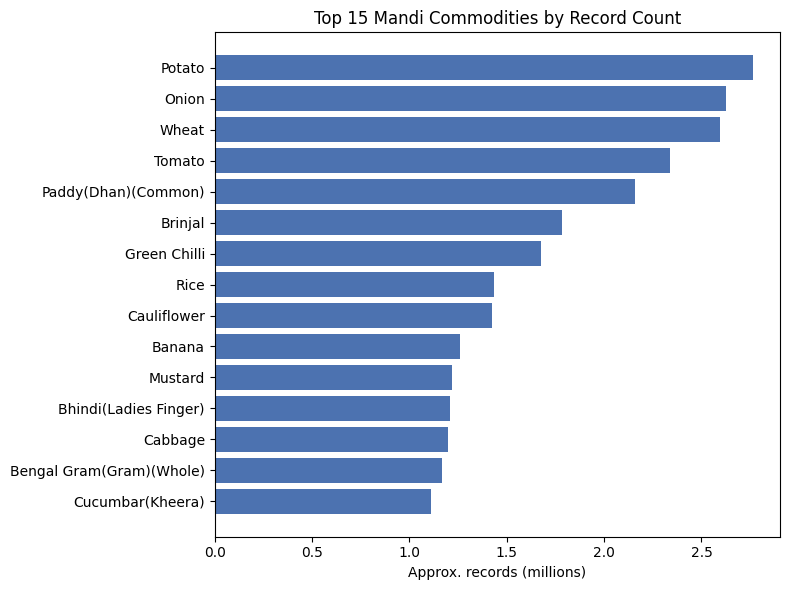

In [6]:
top15 = counts_df.head(15).sort_values("approx_record_count")
plt.figure(figsize=(8, 6))
plt.barh(top15["crop_file_name"], top15["approx_record_count"] / 1e6, color="#4C72B0")
plt.xlabel("Approx. records (millions)")
plt.title("Top 15 Mandi Commodities by Record Count")
plt.tight_layout()
plt.savefig("Outputs/Figures/phase01_top15_mandi_record_counts.png", dpi=150)
plt.show()

### Schema consistency check

A sample of files is loaded with `nrows` only, to confirm the column schema without a full load.

In [7]:
sample_files = ["Onion.csv", "Wheat.csv", "Astera.csv"]
for fname in sample_files:
    raw = pd.read_csv(MANDI_DIR / fname, nrows=3)
    print(f"--- {fname} ---")
    print(list(raw.columns))
    print()

--- Onion.csv ---
['State Name', 'District Name', 'Market Name', 'Variety', 'Group', 'Arrivals (Tonnes)', 'Min Price (Rs./Quintal)', 'Max Price (Rs./Quintal)', 'Modal Price (Rs./Quintal)', 'Reported Date']

--- Wheat.csv ---
['State Name', 'District Name', 'Market Name', 'Variety', 'Group', 'Arrivals (Tonnes)', 'Min Price (Rs./Quintal)', 'Max Price (Rs./Quintal)', 'Modal Price (Rs./Quintal)', 'Reported Date']

--- Astera.csv ---
['State Name', 'District Name', 'Market Name', 'Variety', 'Group', 'Arrivals', 'Min Price', 'Max Price', 'Modal Price', 'Reported Date']



### Observation

Column naming is **not fully standardized** across the 325 files: most use units in the column name (`Arrivals (Tonnes)`, `Min Price (Rs./Quintal)`), but some (e.g. `Astera.csv`) omit the units (`Arrivals`, `Min Price`). `Code/utils/data_audit.py` already includes a `MANDI_COLUMN_ALIASES` map and a `load_mandi_file()` loader that normalizes this, for reuse from Phase 2 onward. Five files (`Jaggery`, `Ladies Finger`, `Nargasi`, `Saffron`, `Seegu`) contain a header row only with zero data rows and must be excluded from the Phase 2 candidate pool.

In [8]:
date_samples = {}
for fname in ["Onion.csv", "Potato.csv", "Wheat.csv", "Tomato.csv", "Ajwan.csv", "Amaranthus.csv"]:
    with open(MANDI_DIR / fname, encoding="utf-8") as f:
        next(f)
        first_row = next(f)
    date_samples[fname] = first_row.strip().split(",")[-1]
print("Sample 'Reported Date' raw values by file:")
for k, v in date_samples.items():
    print(f"  {k:20s} -> {v}")

Sample 'Reported Date' raw values by file:
  Onion.csv            -> 09 Feb 2006
  Potato.csv           -> 09 Feb 2006
  Wheat.csv            -> 08 Apr 2005
  Tomato.csv           -> 19 Aug 2013
  Ajwan.csv            -> 2005-03-24
  Amaranthus.csv       -> 2005-07-26


### Observation

`Reported Date` is stored in **at least two different formats** across files — `DD Mon YYYY` (e.g. `Onion.csv`, `Potato.csv`, `Wheat.csv`) and ISO `YYYY-MM-DD` (e.g. `Ajwan.csv`, `Amaranthus.csv`). Any date parsing in later phases must handle both formats explicitly (`Code/utils/data_audit.py:parse_mixed_dates()` already does this with `format="mixed"`) rather than assuming one format project-wide.

In [9]:
onion_sample = load_mandi_file("Onion.csv", nrows=200_000)
onion_sample["Reported Date"] = parse_mixed_dates(onion_sample["Reported Date"])
print("Onion.csv (first 200k rows) — columns:", list(onion_sample.columns))
print("States:", onion_sample['State Name'].nunique(), "| Districts:", onion_sample['District Name'].nunique(),
      "| Markets:", onion_sample['Market Name'].nunique(), "| Varieties:", onion_sample['Variety'].nunique())
print("Date range in this sample:", onion_sample["Reported Date"].min(), "to", onion_sample["Reported Date"].max())
display(onion_sample.head(3))

Onion.csv (first 200k rows) — columns: ['State Name', 'District Name', 'Market Name', 'Variety', 'Group', 'Arrivals (Tonnes)', 'Min Price (Rs./Quintal)', 'Max Price (Rs./Quintal)', 'Modal Price (Rs./Quintal)', 'Reported Date']
States: 8 | Districts: 89 | Markets: 288 | Varieties: 25
Date range in this sample: 2002-02-01 00:00:00 to 2024-02-02 00:00:00


,State Name,District Name,Market Name,Variety,Group,Arrivals (Tonnes),Min Price (Rs./Quintal),Max Price (Rs./Quintal),Modal Price (Rs./Quintal),Reported Date
0,Arunachal Pradesh,Tawang,Tawang,Other,Vegetables,0.9,1200.0,1600.0,1500.0,2006-02-09
1,Arunachal Pradesh,Tawang,Tawang,Other,Vegetables,0.9,1500.0,2000.0,1800.0,2006-02-07
2,Arunachal Pradesh,Tawang,Tawang,Other,Vegetables,0.7,1500.0,2000.0,1800.0,2006-01-24


### Observation

The mandi schema (`State Name, District Name, Market Name, Variety, Group, Arrivals (Tonnes), Min/Max/Modal Price (Rs./Quintal), Reported Date`) is consistent in *meaning* across files even where column labels differ slightly. `Arrivals (Tonnes)` is the quantity of produce arriving at the mandi — this is a **supply-side market-activity measure**, not a consumer demand figure, and will be labeled as such throughout the project.

<a id="5"></a>
## 5. APY Dataset — crop-wise-area-production-yield.csv

### Load and profile structure

This is a single ~56 MB file, small enough to load fully for structural inspection (no cleaning performed here).

In [10]:
apy_path = Path("Dataset/crop-wise-area-production-yield.csv")
apy = pd.read_csv(apy_path)
print("Rows:", f"{len(apy):,}", "| Columns:", len(apy.columns))
print(list(apy.columns))
apy.dtypes

Rows: 455,359 | Columns: 16
['id', 'year', 'state_name', 'state_code', 'district_name', 'district_code', 'crop_name', 'crop_code', 'crop_type', 'season', 'area', 'area_unit', 'production', 'production_unit', 'yield', 'yield_unit']


id                   int64
year                object
state_name          object
state_code           int64
district_name       object
district_code        int64
crop_name           object
crop_code          float64
crop_type           object
season              object
area               float64
area_unit           object
production         float64
production_unit     object
yield              float64
yield_unit          object
dtype: object

In [11]:
missing = apy.isnull().sum()
missing_pct = (missing / len(apy) * 100).round(2)
display(pd.DataFrame({"missing_count": missing, "missing_pct": missing_pct}))
print("Duplicate rows:", f"{apy.duplicated().sum():,}")
print("Year range:", apy['year'].min(), "to", apy['year'].max(), "| Distinct years:", apy['year'].nunique())
print("States:", apy['state_name'].nunique(), "| Districts:", apy['district_name'].nunique(),
      "| Crops:", apy['crop_name'].nunique(), "| Seasons:", apy['season'].nunique())

,missing_count,missing_pct
id,0,0.0
year,0,0.0
state_name,0,0.0
state_code,0,0.0
district_name,0,0.0
district_code,0,0.0
crop_name,0,0.0
crop_code,21,0.0
crop_type,0,0.0
season,0,0.0


Duplicate rows: 0
Year range: 1997-1998 to 2022-2023 | Distinct years: 26
States: 34 | Districts: 737 | Crops: 115 | Seasons: 7


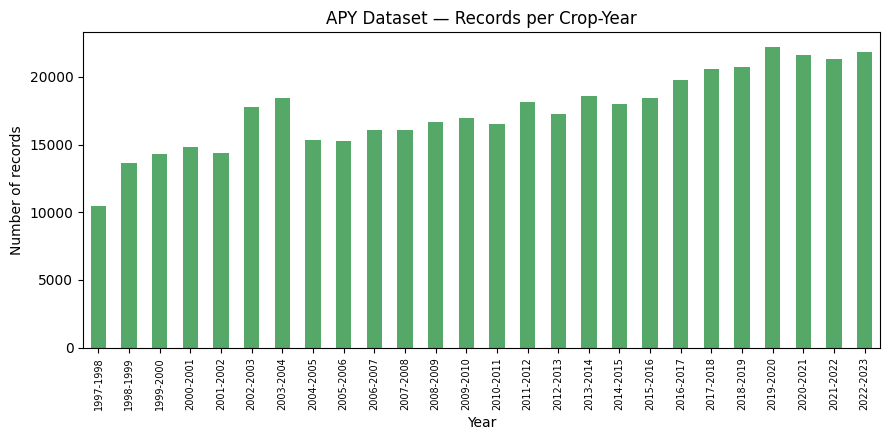

In [12]:
apy_year_counts = apy['year'].value_counts().sort_index()
plt.figure()
apy_year_counts.plot(kind="bar", color="#55A868")
plt.title("APY Dataset — Records per Crop-Year")
plt.xlabel("Year")
plt.ylabel("Number of records")
plt.xticks(rotation=90, fontsize=7)
plt.tight_layout()
plt.savefig("Outputs/Figures/phase01_apy_records_per_year.png", dpi=150)
plt.show()

### Observation

The APY dataset covers **26 crop-years (1997-98 to 2022-23)** across 115 distinct crops at district-level granularity, with `area` (Hectares), `production` (Tonnes) and `yield` (Tonnes/Hectare) as the core numeric fields. Missingness and duplicate handling are deferred to Phase 5 — here we only confirm their presence so Phase 2 can factor completeness into crop scoring.

<a id="6"></a>
## 6. APY Codebook — Crop_Wise_Area_Production_Yield_codebook.xlsx

### Read field definitions and dataset metadata

The codebook is opened read-only (`data_only=True`) purely for interpretation; it is never written to.

In [13]:
import openpyxl

wb = openpyxl.load_workbook("Dataset/Crop_Wise_Area_Production_Yield_codebook.xlsx", data_only=True)
print("Sheets:", wb.sheetnames)

codebook_rows = list(wb["Codebook"].iter_rows(values_only=True))
codebook_df = pd.DataFrame(codebook_rows[2:], columns=codebook_rows[1])
display(codebook_df)

meta_rows = list(wb["Metadata Information"].iter_rows(values_only=True))
for row in meta_rows:
    if row[0] and row[1]:
        print(f"{row[0]}: {row[1]}")

Sheets: ['Codebook', 'Metadata Information']


,Variable Name,Variable Description,Variable Type,Unit Of Measurement,Unit Type
0,year,Year,TEXT,None,Categorical
1,state_name,State Name,TEXT,None,Categorical
2,state_code,State Code,TEXT,None,Categorical
3,district_name,District Name,TEXT,None,Categorical
4,district_code,District Code,TEXT,None,Categorical
5,crop_name,Crop Name,TEXT,None,Categorical
6,crop_code,Crop Code,TEXT,None,Categorical
7,crop_type,Crop Type,TEXT,None,Categorical
8,season,Season,TEXT,None,Categorical
9,area,Area,NUMERIC,Hectares,Area


Dataset Name: Crop Wise Area Production Yield
Granularity Level: District
Frequency: Yearly
Data Retrieval Date: 26-02-2026
Data Last Updated: 14-12-2023
Data Extraction Page: https://data.desagri.gov.in/website/crops-apy-report-web
About: The Crop Wise Area Production Yield dataset reports crop-wise area, production, and yield across states and districts in India. It records annual agricultural statistics by crop and season, capturing the scale of cultivation and output performance. The data supports assessment of crop productivity patterns and regional differences over time. It is relevant for analyzing agricultural growth, crop diversification, and the spatial distribution of farm output.
Methodology: The data originates from the Directorate of Economics and Statistics under the Ministry of Agriculture and Farmers Welfare, Government of India. State and district authorities compile crop statistics through administrative reporting systems based on field surveys and revenue records. F

### Observation

The codebook confirms official provenance: the dataset originates from the **Directorate of Economics and Statistics, Ministry of Agriculture and Farmers Welfare, Government of India** (via `data.desagri.gov.in`), at **district-level granularity, yearly frequency**, last updated 14-12-2023. Units are explicit: Area = Hectares, Production = Tonnes, Yield = Tonnes/Hectare. This official sourcing is a positive feasibility signal for any crop well covered here.

<a id="7"></a>
## 7. Agri Market Dataset.csv

### Load and profile structure

This dataset is small enough (~39k rows) to load and profile fully.

In [14]:
agri_market = pd.read_csv("Dataset/Agri Market Dataset.csv")
print("Rows:", f"{len(agri_market):,}", "| Columns:", len(agri_market.columns))
display(agri_market.dtypes)
print("Duplicate rows:", agri_market.duplicated().sum())
display(agri_market.isnull().sum())

Rows: 39,060 | Columns: 11


State Name                   object
District Name                object
Market Name                  object
Commodity                    object
Variety                      object
Group                        object
Arrivals (Tonnes)            object
Min Price (Rs./Quintal)       int64
Max Price (Rs./Quintal)       int64
Modal Price (Rs./Quintal)     int64
Reported Date                object
dtype: object

Duplicate rows: 0


State Name                   0
District Name                0
Market Name                  0
Commodity                    0
Variety                      0
Group                        0
Arrivals (Tonnes)            0
Min Price (Rs./Quintal)      0
Max Price (Rs./Quintal)      0
Modal Price (Rs./Quintal)    0
Reported Date                0
dtype: int64

In [15]:
agri_market["Reported Date"] = pd.to_datetime(agri_market["Reported Date"], errors="coerce")
print("Date range:", agri_market["Reported Date"].min(), "to", agri_market["Reported Date"].max())
print("\nStates covered:", agri_market["State Name"].unique())
print("Districts covered:", agri_market["District Name"].unique())
print("Number of markets:", agri_market["Market Name"].nunique())
print("\nCommodities covered:")
display(agri_market["Commodity"].value_counts())

arrivals_numeric = pd.to_numeric(agri_market["Arrivals (Tonnes)"], errors="coerce")
print("\nNon-numeric 'Arrivals (Tonnes)' values:", arrivals_numeric.isna().sum(), "out of", len(agri_market))

Date range: 2020-01-01 00:00:00 to 2024-12-05 00:00:00

States covered: ['Maharashtra']
Districts covered: ['Amarawati' 'Akola' 'Vashim' 'Wardha' 'Yavatmal']
Number of markets: 26

Commodities covered:


Commodity
Soyabean                       12832
Arhar (Tur/Red Gram)(Whole)    11819
Wheat                           9569
Jowar(Sorghum)                  2728
Cotton                          2112
Name: count, dtype: int64


Non-numeric 'Arrivals (Tonnes)' values: 169 out of 39060


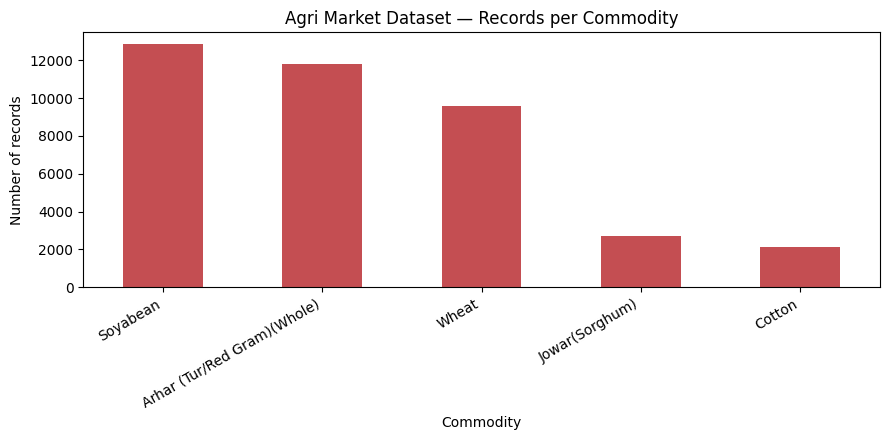

In [16]:
commodity_counts = agri_market["Commodity"].value_counts()
plt.figure()
commodity_counts.plot(kind="bar", color="#C44E52")
plt.title("Agri Market Dataset — Records per Commodity")
plt.ylabel("Number of records")
plt.xticks(rotation=30, ha="right")
plt.tight_layout()
plt.savefig("Outputs/Figures/phase01_agrimarket_commodity_counts.png", dpi=150)
plt.show()

### Observation — terminology and a critical geographic limitation

`Arrivals (Tonnes)` here has the same meaning as in the mandi dataset — **quantity arriving at market (supply-side market activity)** — not consumer demand. There is **no field in this dataset that represents actual consumer demand**; none should be fabricated later.

More importantly: this dataset is **not national**. It covers exactly **one state (Maharashtra)**, **5 districts** (Amravati division: Amravati, Akola, Vashim, Wardha, Yavatmal), **26 markets**, **5 commodities** (Soyabean, Arhar, Wheat, Jowar, Cotton), over **2020–2024**. This is a materially narrower dataset than the nationwide mandi data. It can only serve as a **regional validation/cross-check source** for whichever selected crops it happens to cover, restricted to that region — it cannot be treated as a general national market-activity source. This must be factored explicitly into Phase 2's scoring rather than being a hard requirement for all three final crops.

<a id="8"></a>
## 8. final_data.csv

### Load and inspect structure and purpose

In [17]:
final_data = pd.read_csv("Dataset/final_data.csv")
print("Rows:", f"{len(final_data):,}", "| Columns:", len(final_data.columns))
display(final_data.head(5))
display(final_data.nunique())
print("Duplicate rows:", final_data.duplicated().sum())

Rows: 4,151 | Columns: 6


,State,State_code,District,District_code,Market_code,Market
0,Andaman and Nicobar,AN,Nicobar,2,4362,Car Nicobar
1,Andaman and Nicobar,AN,North and Middle Andaman,3,4364,Diglipur
2,Andaman and Nicobar,AN,North and Middle Andaman,3,4363,Mayabandar
3,Andaman and Nicobar,AN,South Andaman,1,366,Port Blair
4,Andhra Pradesh,AP,Anantapur,12,873,Anantapur


State              36
State_code         36
District          603
District_code      83
Market_code      4151
Market           4077
dtype: int64

Duplicate rows: 0


### Observation

`final_data.csv` contains only `State, State_code, District, District_code, Market_code, Market` — **no prices, no production, no dates**. It is a **State → District → Market reference/lookup table** (likely a market master list used for ID standardization), not a source of price, supply or demand information itself. Its role in the project is to help standardize market identifiers during Phase 4 integration if market names differ across the mandi files. It does **not** contain geographic coordinates, which matters for the future logistics/weather-mapping phases (see Limitations).

<a id="9"></a>
## 9. Weather API (Open-Meteo) — Existing Script Review

### Inspect Code/test_openmeteo.py without invoking the API

Per Phase 1 scope, the API is **not called** in this notebook — only the existing script's structure is reviewed. A live connectivity test and full collection workflow belong to Phase 3.

In [18]:
print(Path("Code/test_openmeteo.py").read_text(encoding="utf-8"))

import requests

# Test location: Ludhiana, Punjab
latitude = 30.9010
longitude = 75.8573

url = "https://archive-api.open-meteo.com/v1/archive"

params = {
    "latitude": latitude,
    "longitude": longitude,

    # Small date range for testing
    "start_date": "2024-01-01",
    "end_date": "2024-01-07",

    # Weather variables we potentially need
    "daily": [
        "temperature_2m_mean",
        "temperature_2m_max",
        "temperature_2m_min",
        "rain_sum",
        "relative_humidity_2m_mean",
        "wind_speed_10m_mean",
        "et0_fao_evapotranspiration"
    ],

    "timezone": "Asia/Kolkata"
}

print("Testing Open-Meteo Historical Weather API...")
print("Location:", latitude, longitude)
print("Date:", params["start_date"], "to", params["end_date"])

try:
    response = requests.get(
        url,
        params=params,
        timeout=(10, 60)
    )

    print("\nStatus:", response.status_code)

    if response.status_code == 200:

        data = response.json()

### Observation

The existing script demonstrates a **working, key-less** call to the Open-Meteo Historical Weather Archive API (`https://archive-api.open-meteo.com/v1/archive`) for one hardcoded location (Ludhiana, Punjab) and a 7-day window, requesting `temperature_2m_mean/max/min`, `rain_sum`, `relative_humidity_2m_mean`, `wind_speed_10m_mean`, and `et0_fao_evapotranspiration` as daily variables, with `timezone="Asia/Kolkata"`. It has minimal error handling (`Timeout`/`RequestException` only), no caching, no support for multiple locations/date ranges, and no persistence to disk. Phase 3 needs to generalize this into a batch, cached, validated collector — see Section 14 (Requirements for Phase 2) and `Documentation/Future_Work_Roadmap.md`.

<a id="10"></a>
## 10. Existing Code Audit

| Script | Purpose | Reusable logic | Hardcoded assumptions | Disposition |
|---|---|---|---|---|
| `Code/inspect_agriculture.py` | One-off console audit of the APY dataset, plus a hardcoded Tomato/Onion/Potato deep-dive | Missing-value table, duplicate check, describe-stats pattern | Assumes Tomato/Onion/Potato are the crops of interest | **REFACTORED** — its generic logic is now in `Code/utils/data_audit.py`; the file itself is kept unmodified for reference and will be removed once Phase 2 confirms no unique logic remains |
| `Code/inspect_top.py` | One-off console audit of Tomato/Onion/Potato mandi files specifically | Date parsing, per-crop states/districts/markets/varieties counts, price describe-stats | Hardcoded crop list `["Tomato", "Onion", "Potato"]`, assumes uniform column names (breaks on files like `Astera.csv`) | **REFACTORED** — generalized into `list_mandi_crop_files()` / `load_mandi_file()` / `mandi_file_record_count()` in `Code/utils/data_audit.py`, which work for any of the 325 files; original kept for reference, not yet deleted |
| `Code/test_openmeteo.py` | Smoke-tests the Open-Meteo API for one hardcoded location/date range | Confirms the endpoint, parameter shape, and key-less access work | Hardcoded lat/lon, tiny date window, no caching/persistence | **KEEP as reference, REPLACE functionally in Phase 3** with a proper `Code/weather/collector.py` (batch locations, caching, validation, logging) |

No file has been deleted in Phase 1. `Code/utils/__init__.py` and `Code/utils/data_audit.py` are new, reusable, crop-agnostic modules created to support this and future notebooks.

<a id="11"></a>
## 11. Cross-Dataset Compatibility (Initial Check)

### Compare crop-name universes across the three tabular sources

This is a first-pass, exact-string check only — fuzzy/manual name reconciliation is Phase 2/4 work.

In [19]:
mandi_crop_names = {f[:-4].strip().lower() for f in crop_files}
apy_crop_names = set(apy["crop_name"].dropna().astype(str).str.strip().str.lower().unique())
agri_market_crop_names = set(agri_market["Commodity"].dropna().astype(str).str.strip().str.lower().unique())

print("Mandi candidate crops:", len(mandi_crop_names))
print("APY crops:", len(apy_crop_names))
print("Agri Market crops:", len(agri_market_crop_names))

print("\nExact-name overlap: Mandi ∩ APY:", len(mandi_crop_names & apy_crop_names))
print("Exact-name overlap: Mandi ∩ Agri Market:", len(mandi_crop_names & agri_market_crop_names))
print("Exact-name overlap: APY ∩ Agri Market:", len(apy_crop_names & agri_market_crop_names))

print("\nAgri Market commodities and their exact-match status against Mandi filenames:")
for c in sorted(agri_market_crop_names):
    print(f"  {c:30s} in mandi filenames: {c in mandi_crop_names} | in APY: {c in apy_crop_names}")

Mandi candidate crops: 325
APY crops: 115
Agri Market crops: 5

Exact-name overlap: Mandi ∩ APY: 40
Exact-name overlap: Mandi ∩ Agri Market: 4
Exact-name overlap: APY ∩ Agri Market: 2

Agri Market commodities and their exact-match status against Mandi filenames:
  arhar (tur/red gram)(whole)    in mandi filenames: False | in APY: False
  cotton                         in mandi filenames: True | in APY: False
  jowar(sorghum)                 in mandi filenames: True | in APY: False
  soyabean                       in mandi filenames: True | in APY: True
  wheat                          in mandi filenames: True | in APY: True


### Observation

Exact string matching already finds some overlap, but crop names differ in formatting across sources (e.g. mandi's `Arhar (Tur-Red Gram)(Whole)` vs Agri Market's `Arhar (Tur/Red Gram)(Whole)` — different bracket/slash conventions for the same crop). Phase 2 will need a **normalized crop-name mapping**, not exact-string matching, to correctly compute cross-dataset overlap.

In [20]:
mandi_states_sample = set(onion_sample["State Name"].dropna().unique())
apy_states = set(apy["state_name"].dropna().unique())
agri_market_states = set(agri_market["State Name"].dropna().unique())
final_data_states = set(final_data["State"].dropna().unique())

print("States seen in Onion.csv sample:", len(mandi_states_sample))
print("States in APY:", len(apy_states))
print("States in Agri Market:", agri_market_states)
print("States in final_data.csv:", len(final_data_states))
print("\nOnion-sample ∩ APY state names (exact match):", len(mandi_states_sample & apy_states))
print("Onion-sample ∩ final_data state names (exact match):", len(mandi_states_sample & final_data_states))

States seen in Onion.csv sample: 8
States in APY: 34
States in Agri Market: {'Maharashtra'}
States in final_data.csv: 36

Onion-sample ∩ APY state names (exact match): 6
Onion-sample ∩ final_data state names (exact match): 8


### Observation

State names show reasonable exact-match overlap across sources, which is encouraging for future joins at the state level; district and market-name matching will need closer checking in Phase 4, since administrative naming (spelling, abbreviations) commonly differs between government data releases.

<a id="12"></a>
## 12. Initial Limitations

Only limitations actually observed during this phase are listed:

1. **Inconsistent mandi column naming** — some files omit units from column headers (`Arrivals` vs `Arrivals (Tonnes)`), requiring normalization before any cross-file operation.
2. **Inconsistent date formats** in `Reported Date` across mandi files (`DD Mon YYYY` vs ISO `YYYY-MM-DD`) — must be parsed with an explicit mixed-format strategy.
3. **Empty candidate files** — 5 of the 325 mandi files (`Jaggery`, `Ladies Finger`, `Nargasi`, `Saffron`, `Seegu`) contain no data rows and must be excluded from the Phase 2 candidate pool.
4. **Agri Market Dataset has narrow scope** — only 5 commodities, 1 state, 5 districts, 26 markets, 2020–2024 — usable only as a regional validation signal, not a national market-activity source.
5. **No geographic coordinates exist anywhere** in the provided data (`final_data.csv` has only names/codes) — weather mapping and future logistics/routing will require a documented external coordinate source.
6. **Crop-name formatting differs across sources** (bracket/slash conventions, spacing) — exact-string matching under-counts true overlap; a normalized mapping is required.
7. **Large mandi file sizes** (up to ~230 MB per crop) make full in-memory loads for all 325 files impractical; per-file line counts and column-limited/sampled reads are required for Phase 2's full audit.
8. **`Arrivals (Tonnes)` in Agri Market Dataset is stored as text** with 169 non-numeric values in the sampled column, requiring coercion/cleaning before numeric use.
9. **No true demand variable exists** in any source — only supply-side arrivals/traded-quantity signals are available; this proxy limitation must be carried through to the future Phase 9 specification.

<a id="13"></a>
## 13. Phase 1 Summary — Dataset Inventory Table

| Dataset | Source | Purpose | Rows (approx.) | Columns | Date Range | Geographic Level | Crop Coverage | Key Variables | Units | Missingness Observed | Role in Project |
|---|---|---|---|---|---|---|---|---|---|---|---|
| India Commodity Wise Mandi Dataset (325 files) | Government mandi/APMC price reporting (per-crop CSVs) | Historical price + arrivals per market | ~56.9M across all files (e.g. Potato 2.76M, Onion 2.62M) | 10 (schema varies slightly) | Earliest samples ~2005 (varies by file) | State/District/Market/Variety | 325 candidate crops (320 with data) | Arrivals (Tonnes), Min/Max/Modal Price (Rs./Quintal) | Tonnes; Rs./Quintal | Not yet profiled at scale (Phase 2) | Primary price + arrivals source |
| crop-wise-area-production-yield.csv | data.desagri.gov.in (Govt. of India) | Crop production/area/yield | ~ hundreds of thousands (district-crop-year grain) | 16 | 1997-98 to 2022-23 (26 years) | State/District | 115 crops | area, production, yield | Hectares; Tonnes; Tonnes/Hectare | Present, not yet quantified precisely | Primary supply/production source |
| Agri Market Dataset.csv | Kaggle (unspecified upstream) | Secondary arrivals/price snapshot | 39,060 | 11 | 2020–2024 | 1 state, 5 districts, 26 markets (Maharashtra/Amravati only) | 5 crops (Soyabean, Arhar, Wheat, Jowar, Cotton) | Arrivals (Tonnes), Min/Max/Modal Price | Tonnes; Rs./Quintal | 0 nulls; 169 non-numeric Arrivals values | Regional validation source only |
| final_data.csv | Unspecified (appears to be an official market master list) | Market/district/state ID lookup | 4,152 | 6 | N/A (no dates) | State/District/Market | N/A | State/District/Market names + codes | N/A | 0 nulls observed | ID standardization aid for Phase 4 |
| Open-Meteo Historical Weather API | Open-Meteo (open, key-less) | Historical daily weather | On-demand (not yet collected) | Varies by variable selection | Any historical range supported | Point coordinate (lat/lon) | N/A | temperature, rain, humidity, wind, ET0 | °C; mm; %; km/h | N/A — not yet collected | External weather source for Phase 3 |

All numbers above come directly from the inspections executed in this notebook; exact mandi-file-level completeness statistics are deferred to Phase 2's full audit.

<a id="14"></a>
## 14. Requirements for Phase 2

Phase 2 (Crop Feasibility Audit & Selection) needs the following, all now available from this phase:

**Candidate crop universe**: 325 mandi filenames (`Processed_Data/phase1_mandi_file_record_counts.csv`), minus the 5 confirmed-empty files → 320 real candidates. Cross-referenced against 115 APY `crop_name` values and 5 Agri Market `Commodity` values via a **normalized name mapping** (not exact string match — see Section 11).

**Metrics to calculate per candidate crop** (mandi): rows, date range, years, states/districts/markets/varieties, price & arrivals missing %, duplicates, temporal continuity (gaps between reporting dates). (APY): years, states/districts, production/area/yield completeness, seasonal coverage. (Agri Market, where applicable): treat as bonus/validation signal only, not a hard requirement, given its Maharashtra-only, 5-crop scope established in Section 7.

**Cross-dataset overlap checks**: crop-name normalization map; state/district name reconciliation (Section 11 found exact-match overlap encouraging at state level, unverified at district level).

**Data-quality checks**: reuse `Code/utils/data_audit.py` (`load_mandi_file`, `parse_mixed_dates`, `basic_csv_profile`) so column-naming and date-format inconsistencies (Section 4) are handled uniformly across all 320 files.

**Expected output**: a transparent, non-composite-score comparison table across candidates, supporting visualizations (coverage, missingness, historical span, cross-dataset overlap), and a final, evidence-based selection of exactly three crops with documented rationale — to be written into `Notebooks/Phase_02_Crop_Feasibility_Analysis.ipynb` and `Documentation/Master_Project_Context.md`.